centroids are: [[7.25       8.125     ]
 [2.83333333 3.75      ]]
labels: [1 1 1 0 1 1 1 0 0 0]


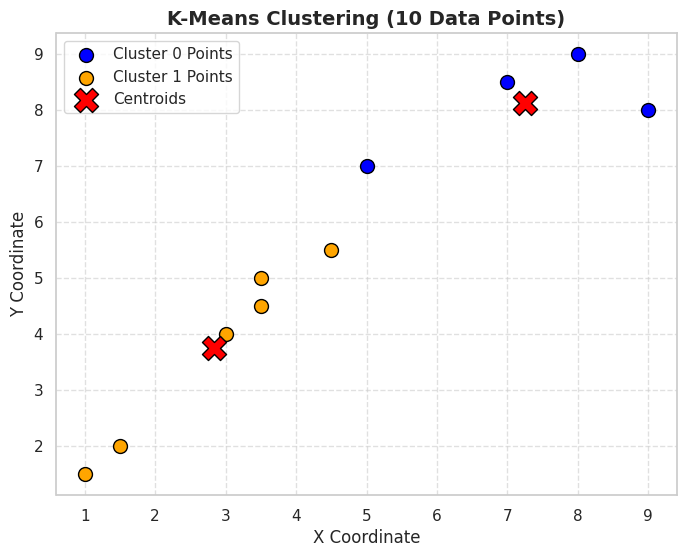

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

X = np.array([
    [1.0, 1.5], [1.5, 2.0], [3.0, 4.0], [5.0, 7.0], [3.5, 5.0],
    [4.5, 5.5], [3.5, 4.5], [8.0, 9.0], [7.0, 8.5], [9.0, 8.0]
])

k = 2

np.random.seed(42)
initial_indices = np.random.choice(X.shape[0], k, replace=False)
centroids = X[initial_indices]

def kmeans(X, k, centroids, max_iters=100):
    for iteration in range(max_iters):
        distances = np.linalg.norm(X[:, np.newaxis, :] - centroids[np.newaxis, :, :], axis=2)
        labels = np.argmin(distances, axis=1)

        new_centroids = np.array([
            X[labels == i].mean(axis=0) if len(X[labels == i]) > 0 else centroids[i]
            for i in range(k)
        ])

        if np.allclose(centroids, new_centroids):
            break

        centroids = new_centroids

    return centroids, labels

final_centroids, final_labels = kmeans(X, k, centroids)

plt.figure(figsize=(8, 6))


colors = ['blue', 'orange']


for i in range(k):
    cluster_points = X[final_labels == i]
    plt.scatter(cluster_points[:, 0], cluster_points[:, 1],
                s=100, c=colors[i], label=f'Cluster {i} Points', edgecolors='black', zorder=2)
print("centroids are:",final_centroids)
print("labels:",final_labels)

plt.scatter(final_centroids[:, 0], final_centroids[:, 1],
            s=300, c='red', marker='X', label='Centroids', edgecolors='black', zorder=3)

plt.title('K-Means Clustering (10 Data Points)', fontsize=14, fontweight='bold')
plt.xlabel('X Coordinate', fontsize=12)
plt.ylabel('Y Coordinate', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6, zorder=1)
plt.legend(loc='upper left')


plt.show()


final medoid: [[8 9]
 [2 3]]
cluster labels: [1 1 1 0 0 0 1 0 1 1]


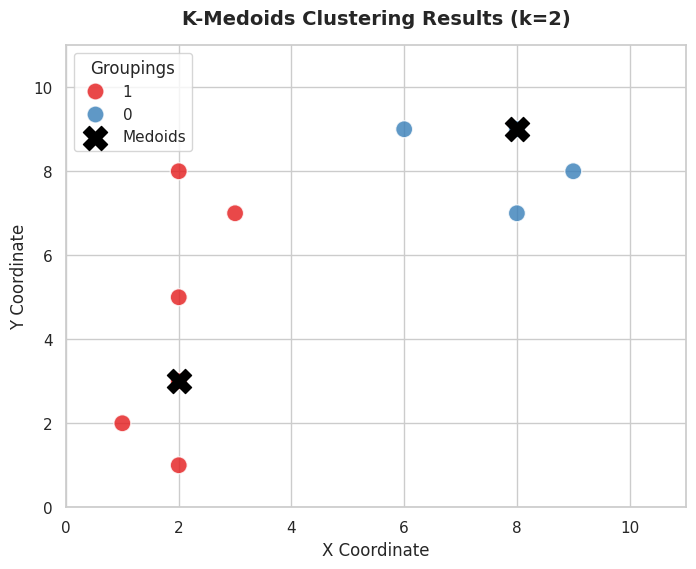

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

points = np.array([
    [1, 2], [2, 1], [2, 3],
    [8, 9], [9, 8], [8, 7],
    [3,7],[6,9],[2,8],[2,5]
])

def manhattan_distance(a, b):
    return np.sum(np.abs(a - b))

def k_medoids(data, k, max_iters=100):
    np.random.seed(42)
    medoid_indices = np.random.choice(len(data), k, replace=False)
    medoids = data[medoid_indices]

    for _ in range(max_iters):
        labels = []
        for point in data:
            distances = [manhattan_distance(point, m) for m in medoids]
            labels.append(np.argmin(distances))
        labels = np.array(labels)

        new_medoids = medoids.copy()
        for i in range(k):
            cluster_points = data[labels == i]
            if len(cluster_points) == 0:
                continue
            costs = [np.sum([manhattan_distance(p, cp) for cp in cluster_points]) for p in cluster_points]
            new_medoids[i] = cluster_points[np.argmin(costs)]

        if np.all(medoids == new_medoids):
            break
        medoids = new_medoids

    return medoids, labels

final_medoids, cluster_labels = k_medoids(points, k=2)

df = pd.DataFrame(points, columns=['X', 'Y'])
df['Cluster'] = cluster_labels.astype(str)

plt.figure(figsize=(8, 6))
sns.set_theme(style="whitegrid")


sns.scatterplot(
    data=df,
    x='X',
    y='Y',
    hue='Cluster',
    palette='Set1',
    s=150,
    alpha=0.8,
    legend='full'
)


plt.scatter(
    final_medoids[:, 0],
    final_medoids[:, 1],
    marker='X',
    s=300,
    color='black',
    label='Medoids',
    zorder=5
)

print("final medoid:",final_medoids)
print("cluster labels:",cluster_labels)
plt.title('K-Medoids Clustering Results (k=2)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('X Coordinate')
plt.ylabel('Y Coordinate')
plt.xlim(0, 11)
plt.ylim(0, 11)
plt.legend(title='Groupings', loc='upper left')

plt.show()
